The second part of this exercise requires results from the gamma function

gamma(3/2) = gamma(1 + 1/2) = 1/2 gamma(1/2).

gamma(1/2) = sqrt(pi)

so using $y = x^2$, then we essentially solve

$$ C / 4 \sqrt(\pi) = 1 \implies C = 4 / \sqrt(pi)$$

(array([0.01257573, 0.07702636, 0.28766987, 0.24837071, 0.28766987,
        0.41657113, 0.59420334, 0.48102175, 0.64136234, 0.6900933 ,
        0.87244141, 0.74668409, 0.77969539, 0.71681673, 0.89602091,
        0.81742259, 0.74039623, 0.79227112, 0.73882426, 0.6806615 ,
        0.52503681, 0.57376778, 0.49516945, 0.43857866, 0.3332569 ,
        0.40085146, 0.22636318, 0.25465857, 0.20907155, 0.19806778,
        0.09274602, 0.09588996, 0.07073849, 0.06445063, 0.04087113,
        0.047159  , 0.0282954 , 0.01571967, 0.02200753, 0.01257573,
        0.01100377, 0.00785983, 0.00628787, 0.00628787, 0.00314393,
        0.00314393, 0.00157197, 0.00785983, 0.00785983, 0.00157197]),
 array([0.1242602 , 0.18787478, 0.25148937, 0.31510396, 0.37871855,
        0.44233313, 0.50594772, 0.56956231, 0.63317689, 0.69679148,
        0.76040607, 0.82402065, 0.88763524, 0.95124983, 1.01486441,
        1.078479  , 1.14209359, 1.20570817, 1.26932276, 1.33293735,
        1.39655193, 1.46016652, 1.52378111, 1.

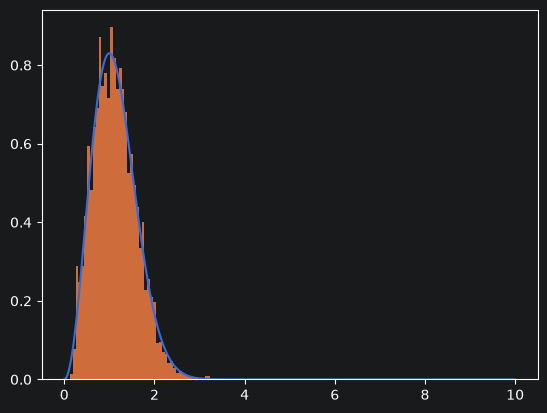

In [18]:
from week11 import *
from scipy.stats import gamma
# Target distribution
f = lambda x : x**2*np.exp(-x**2)

# Propsal sampler and distribution
ppdf = lambda x, given : gamma.pdf(x, a = given**2,
                                   scale = 1 / given,
                                   loc = 0 )
psample = lambda x : gamma.rvs(a = x**2, scale = 1/x, loc = 0 )

S = metropolis_hastings_sampler(proposal_sampler=psample,
                                proposal_density=ppdf,
                                target_density=f,
                                x0= 1,
                                n_samples= 10000)
from scipy.integrate import quad
C = 4 / np.sqrt(np.pi)

import matplotlib.pyplot as plt

xx = np.linspace(0,10, 1000)
plt.plot(xx, f(xx) * C)
plt.hist(S[0], bins = 50, density=True)